# Task 3: Hands-On Data Lab Implementation
Data manipulation, visualization and basic analysis with Python (pandas, NumPy, Matplotlib, Seaborn, SciPy).

Run the cells from top to bottom (Kernel > Restart & Run All).

## Step 1: Import libraries and check versions

In [1]:
%matplotlib inline
import os
import platform
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs("charts", exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 95)
pd.set_option("display.max_columns", 20)

print("Python     :", platform.python_version())
print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)
print("seaborn    :", sns.__version__)

Python     : 3.12.3
pandas     : 3.0.2
numpy      : 2.4.4
matplotlib : 3.10.8
seaborn    : 0.13.2


## Step 2: Create the practice dataset
A realistic e-commerce sales dataset (1,000 orders, year 2025) is generated with a fixed random seed so everyone gets the same data. Missing values and duplicate rows are added on purpose for the cleaning exercise.

In [2]:
rng = np.random.default_rng(42)
n = 1000

catalog = {
    "Electronics":    {"Headphones": 1500, "Smartwatch": 4500, "Power Bank": 1200, "Bluetooth Speaker": 2500},
    "Clothing":       {"T-Shirt": 600, "Jeans": 1800, "Jacket": 3200, "Kurta": 1400},
    "Home & Kitchen": {"Mixer Grinder": 3500, "Cookware Set": 2800, "Water Bottle": 450, "Bedsheet": 1100},
    "Books":          {"Novel": 350, "Self-Help": 450, "Textbook": 900, "Comics": 250},
}
categories = rng.choice(list(catalog), size=n, p=[0.30, 0.28, 0.24, 0.18])
products = [rng.choice(list(catalog[c])) for c in categories]
unit_price = [catalog[c][p] for c, p in zip(categories, products)]

# more orders in the festive months (Oct-Nov)
month_probs = np.array([6, 6, 7, 7, 7, 7, 7, 8, 8, 13, 12, 12], dtype=float)
month_probs /= month_probs.sum()
months = rng.choice(np.arange(1, 13), size=n, p=month_probs)
days = rng.integers(1, 29, size=n)
order_date = pd.to_datetime(pd.DataFrame({"year": 2025, "month": months, "day": days}))

discount = rng.choice([0, 0.05, 0.10, 0.15, 0.20], size=n, p=[0.35, 0.20, 0.20, 0.15, 0.10])
rating = np.clip(np.round(3.4 + 4 * discount + rng.normal(0, 0.9, n)), 1, 5)

raw = pd.DataFrame({
    "order_id": np.arange(1001, 1001 + n),
    "order_date": order_date,
    "region": rng.choice(["North", "South", "East", "West"], size=n, p=[0.30, 0.27, 0.18, 0.25]),
    "category": categories,
    "product": products,
    "quantity": rng.integers(1, 6, size=n),
    "unit_price": unit_price,
    "discount": discount,
    "customer_age": np.clip(rng.normal(32, 9, n).round(), 18, 65),
    "payment_mode": rng.choice(["UPI", "Credit Card", "Debit Card", "Cash on Delivery", "Net Banking"],
                               size=n, p=[0.38, 0.20, 0.18, 0.15, 0.09]),
    "rating": rating,
})

# add missing values and duplicate rows on purpose
for col, frac in [("customer_age", 0.04), ("rating", 0.05), ("region", 0.02)]:
    raw.loc[rng.choice(n, int(n * frac), replace=False), col] = np.nan
raw = pd.concat([raw, raw.sample(20, random_state=1)], ignore_index=True)

raw.to_csv("sales_data.csv", index=False)
print("sales_data.csv saved with", raw.shape[0], "rows and", raw.shape[1], "columns")

sales_data.csv saved with 1020 rows and 11 columns


## Exercise 1: Load and inspect the data

In [3]:
df = pd.read_csv("sales_data.csv", parse_dates=["order_date"])

print("Shape (rows, columns):", df.shape)
print()
print(df.head())
print()
df.info()
print()
print("Missing values per column:")
print(df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Shape (rows, columns): (1020, 11)

   order_id order_date region        category            product  quantity  unit_price  \
0      1001 2025-10-06  North  Home & Kitchen           Bedsheet         2        1100   
1      1002 2025-12-01  North        Clothing            T-Shirt         1         600   
2      1003 2025-06-18   West           Books          Self-Help         3         450   
3      1004 2025-07-20  North  Home & Kitchen       Cookware Set         2        2800   
4      1005 2025-11-22  South     Electronics  Bluetooth Speaker         1        2500   

   discount  customer_age      payment_mode  rating  
0      0.15          27.0               UPI     3.0  
1      0.10          29.0  Cash on Delivery     2.0  
2      0.00          47.0        Debit Card     5.0  
3      0.10          23.0               UPI     5.0  
4      0.00          24.0               UPI     3.0  

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 11 columns):
 # 

## Exercise 2: Data cleaning

In [4]:
print("Rows before cleaning:", len(df))

# 1) remove duplicate rows
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

# 2) handle missing values
df["customer_age"] = df["customer_age"].fillna(df["customer_age"].median())  # numeric -> median
df["rating"] = df["rating"].fillna(df["rating"].median())                    # numeric -> median
df["region"] = df["region"].fillna("Unknown")                                # text -> label

# 3) fix data types
df["customer_age"] = df["customer_age"].astype(int)
df["rating"] = df["rating"].astype(int)

print("Missing values left:", int(df.isna().sum().sum()))
print()
print(df.dtypes)

Rows before cleaning: 1020
Rows after removing duplicates: 1000
Missing values left: 0

order_id                 int64
order_date      datetime64[us]
region                     str
category                   str
product                    str
quantity                 int64
unit_price               int64
discount               float64
customer_age             int64
payment_mode               str
rating                   int64
dtype: object


## Exercise 3: Data manipulation
New columns, filtering, grouping, pivot tables and sorting with pandas.

In [5]:
# New columns (feature engineering)
df["revenue"] = df["quantity"] * df["unit_price"] * (1 - df["discount"])
df["month"] = df["order_date"].dt.month
df["age_group"] = pd.cut(df["customer_age"], bins=[17, 25, 35, 45, 65],
                         labels=["18-25", "26-35", "36-45", "46-65"])
print(df[["order_id", "category", "quantity", "unit_price", "discount", "revenue"]].head())

# Filtering
high_value = df[df["revenue"] > 10000]
print("\nHigh-value orders (revenue > 10,000):", len(high_value))

# Group by + aggregation
cat_summary = (df.groupby("category")
                 .agg(orders=("order_id", "count"),
                      total_revenue=("revenue", "sum"),
                      avg_revenue=("revenue", "mean"),
                      avg_rating=("rating", "mean"))
                 .round(2)
                 .sort_values("total_revenue", ascending=False))
print("\nCategory summary:")
print(cat_summary)

# Pivot table: region x category
pivot = df.pivot_table(index="region", columns="category", values="revenue", aggfunc="sum").round(0)
print("\nRevenue by region and category:")
print(pivot)

# Top 5 products and average revenue per age group
print("\nTop 5 products by revenue:")
print(df.groupby("product")["revenue"].sum().nlargest(5).round(0))
print("\nAverage order value by age group:")
print(df.groupby("age_group", observed=True)["revenue"].mean().round(2))

   order_id        category  quantity  unit_price  discount  revenue
0      1001  Home & Kitchen         2        1100      0.15   1870.0
1      1002        Clothing         1         600      0.10    540.0
2      1003           Books         3         450      0.00   1350.0
3      1004  Home & Kitchen         2        2800      0.10   5040.0
4      1005     Electronics         1        2500      0.00   2500.0

High-value orders (revenue > 10,000): 147

Category summary:
                orders  total_revenue  avg_revenue  avg_rating
category                                                      
Electronics        308      2173735.0      7057.58        3.64
Home & Kitchen     244      1319670.0      5408.48        3.62
Clothing           268      1253270.0      4676.38        3.63
Books              180       223670.0      1242.61        3.69

Revenue by region and category:
category    Books  Clothing  Electronics  Home & Kitchen
region                                                  

## Exercise 4: Data visualization
### Chart 1: Total revenue by category (bar chart)

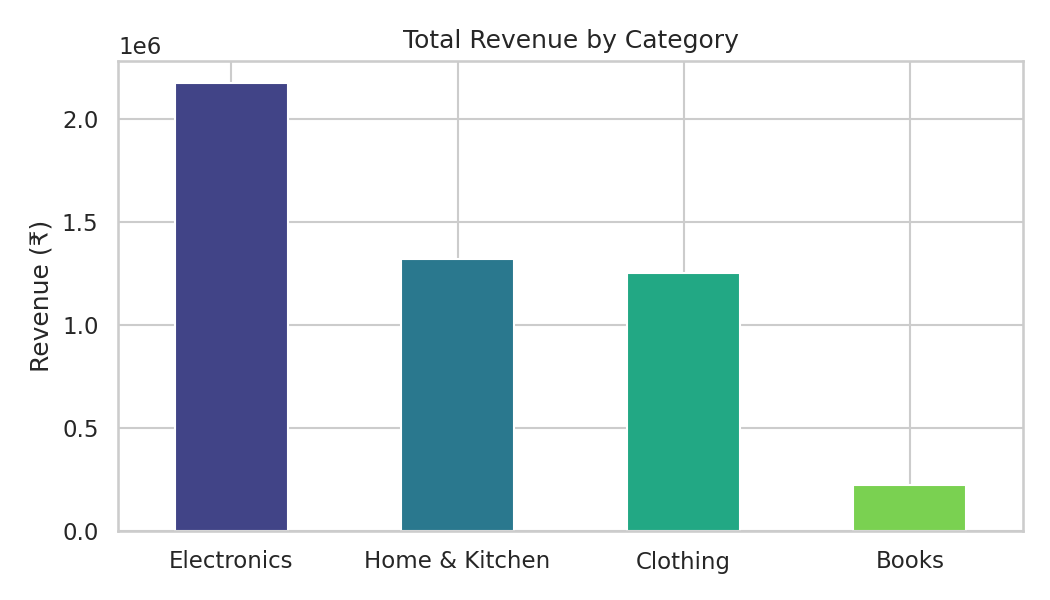

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
cat_summary["total_revenue"].plot(kind="bar", ax=ax, color=sns.color_palette("viridis", 4))
ax.set_title("Total Revenue by Category")
ax.set_ylabel("Revenue (₹)")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("charts/01_revenue_by_category.png", dpi=150)
plt.show()

### Chart 2: Monthly revenue trend (line chart)

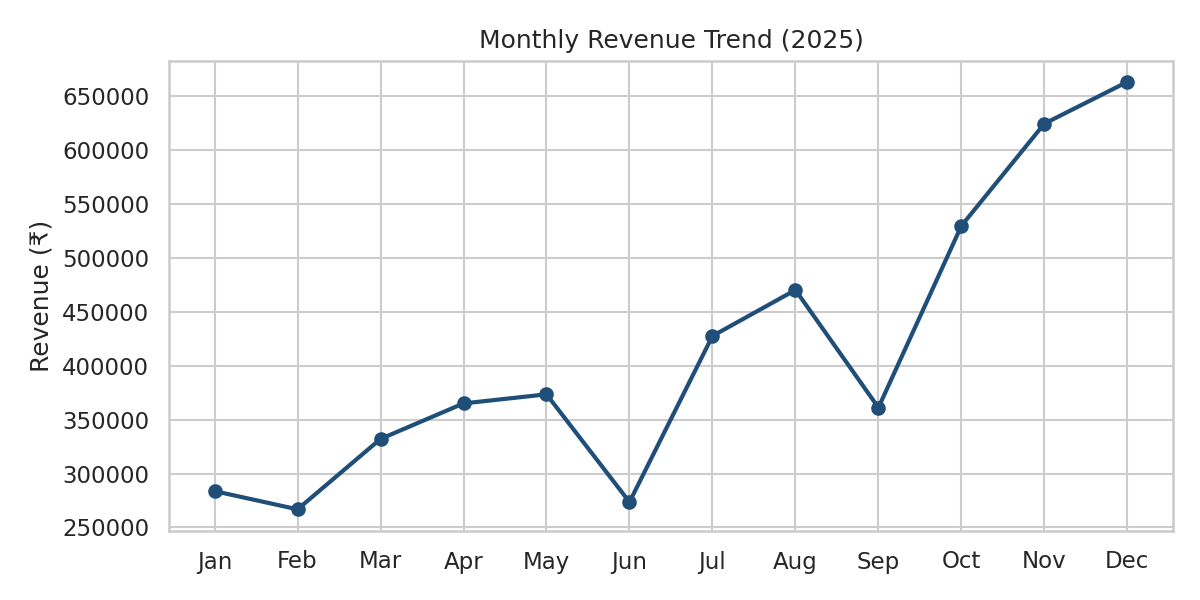

In [7]:
monthly = df.groupby("month")["revenue"].sum()
labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(monthly.index, monthly.values, marker="o", linewidth=2, color="#1F4E79")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(labels)
ax.set_title("Monthly Revenue Trend (2025)")
ax.set_ylabel("Revenue (₹)")
plt.tight_layout()
plt.savefig("charts/02_monthly_revenue.png", dpi=150)
plt.show()

### Chart 3: Customer age distribution (histogram)

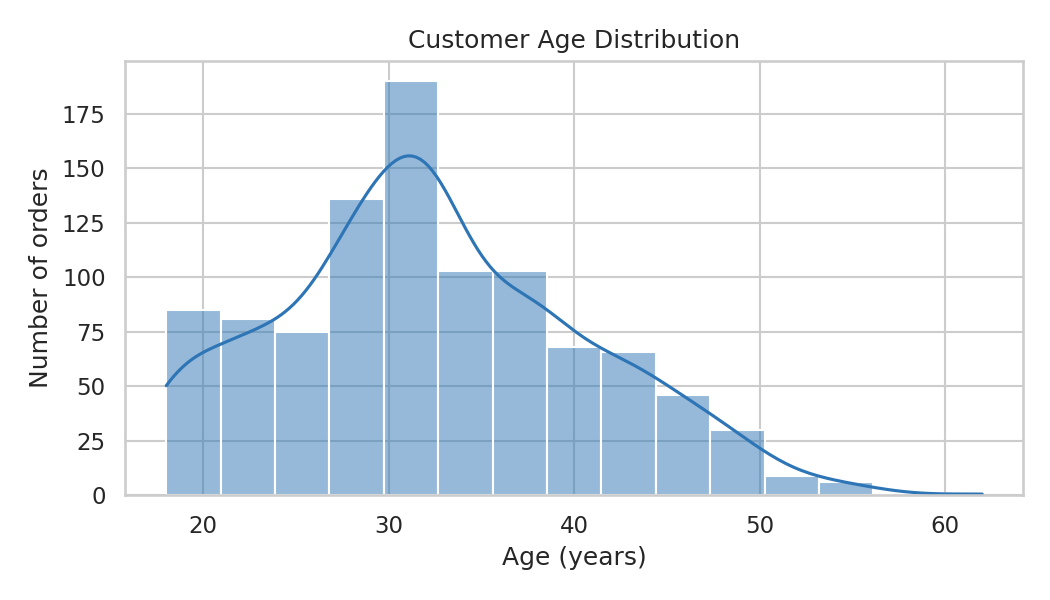

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["customer_age"], bins=15, kde=True, color="#2E75B6", ax=ax)
ax.set_title("Customer Age Distribution")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.savefig("charts/03_age_distribution.png", dpi=150)
plt.show()

### Chart 4: Region vs category revenue (heatmap)

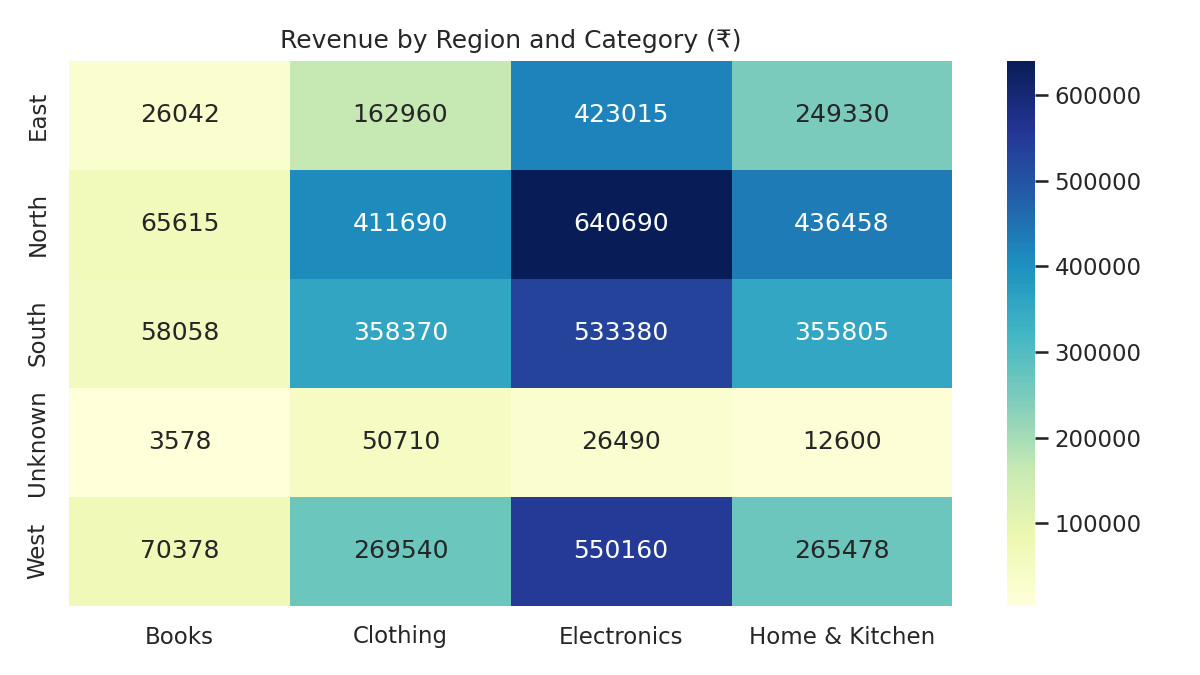

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax)
ax.set_title("Revenue by Region and Category (₹)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("charts/04_region_category_heatmap.png", dpi=150)
plt.show()

## Exercise 5: Basic statistical analysis

Revenue summary:
count     1000.00
mean      4970.34
std       4730.75
min        200.00
25%       1400.00
50%       3240.00
75%       6750.00
max      22500.00
Name: revenue, dtype: float64

Median revenue: 3240.0
Skewness      : 1.46

Correlation matrix:
              quantity  unit_price  discount  customer_age  rating  revenue
quantity          1.00        0.02      0.04         -0.05    0.05     0.52
unit_price        0.02        1.00     -0.06         -0.04   -0.02     0.78
discount          0.04       -0.06      1.00          0.01    0.25    -0.12
customer_age     -0.05       -0.04      0.01          1.00   -0.03    -0.03
rating            0.05       -0.02      0.25         -0.03    1.00    -0.01
revenue           0.52        0.78     -0.12         -0.03   -0.01     1.00

Pearson correlation (discount vs rating): r = 0.251, p-value = 7.232e-16
Average rating, discount >= 10%: 3.86
Average rating, discount <  10%: 3.47
Welch t-test: t = 7.10, p-value = 2.466e-12

Regression: rati

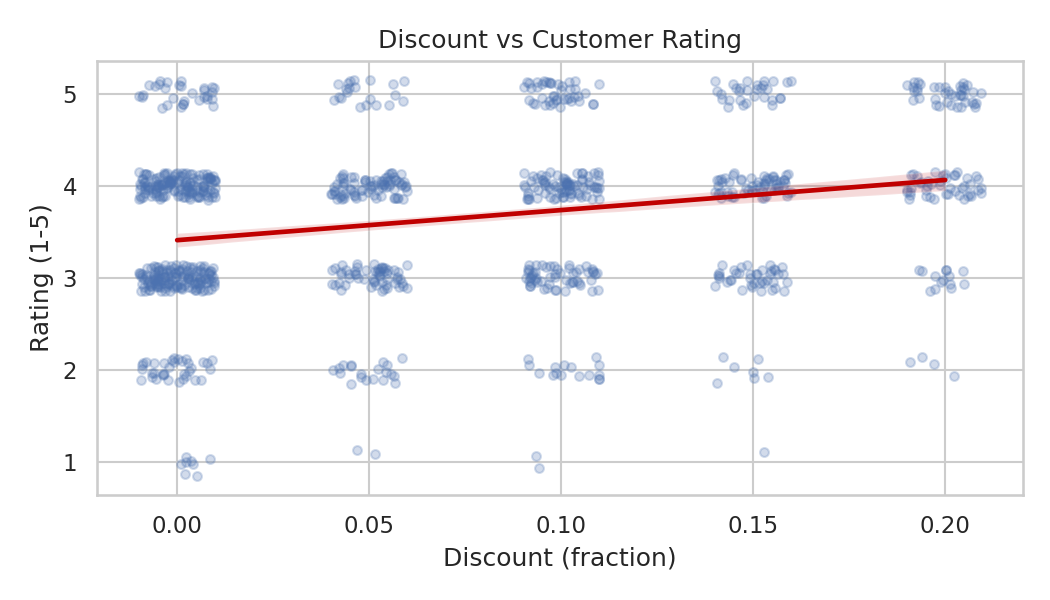

In [10]:
# 1) Descriptive statistics of revenue
print("Revenue summary:")
print(df["revenue"].describe().round(2))
print("\nMedian revenue:", round(df["revenue"].median(), 2))
print("Skewness      :", round(df["revenue"].skew(), 2))

# 2) Correlation matrix
num_cols = ["quantity", "unit_price", "discount", "customer_age", "rating", "revenue"]
print("\nCorrelation matrix:")
print(df[num_cols].corr().round(2))

# 3) Does a higher discount go with a better rating?
r, p = stats.pearsonr(df["discount"], df["rating"])
print(f"\nPearson correlation (discount vs rating): r = {r:.3f}, p-value = {p:.4g}")

high = df.loc[df["discount"] >= 0.10, "rating"]
low = df.loc[df["discount"] < 0.10, "rating"]
t, p2 = stats.ttest_ind(high, low, equal_var=False)
print(f"Average rating, discount >= 10%: {high.mean():.2f}")
print(f"Average rating, discount <  10%: {low.mean():.2f}")
print(f"Welch t-test: t = {t:.2f}, p-value = {p2:.4g}")

# 4) Simple linear regression
lr = stats.linregress(df["discount"], df["rating"])
print(f"\nRegression: rating = {lr.intercept:.2f} + {lr.slope:.2f} x discount  (R-squared = {lr.rvalue**2:.3f})")

fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=df, x="discount", y="rating", x_jitter=0.01, y_jitter=0.15,
            scatter_kws={"alpha": 0.25, "s": 18}, line_kws={"color": "#C00000"}, ax=ax)
ax.set_title("Discount vs Customer Rating")
ax.set_xlabel("Discount (fraction)")
ax.set_ylabel("Rating (1-5)")
plt.tight_layout()
plt.savefig("charts/05_discount_vs_rating.png", dpi=150)
plt.show()

## Step 3: Key findings

In [11]:
known = df[df["region"] != "Unknown"]
best_region = known.groupby("region")["revenue"].sum().idxmax()
pay_share = (df["payment_mode"].value_counts(normalize=True) * 100).round(1)

print("1. Top category      :", cat_summary.index[0], "- Rs", f"{cat_summary['total_revenue'].iloc[0]:,.0f}")
print("2. Best month        :", labels[monthly.idxmax() - 1], "- Rs", f"{monthly.max():,.0f}")
print("3. Top region        :", best_region)
print("4. Most used payment :", pay_share.index[0], f"({pay_share.iloc[0]}% of orders)")
print("5. Average order     : Rs", f"{df['revenue'].mean():,.0f}", "| Median: Rs", f"{df['revenue'].median():,.0f}")
print("6. Festive share     :", f"{monthly.loc[[10, 11, 12]].sum() / monthly.sum() * 100:.1f}% of revenue came from Oct-Dec")

1. Top category      : Electronics - Rs 2,173,735
2. Best month        : Dec - Rs 663,070
3. Top region        : North
4. Most used payment : UPI (36.4% of orders)
5. Average order     : Rs 4,970 | Median: Rs 3,240
6. Festive share     : 36.6% of revenue came from Oct-Dec
